In [60]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready')


Model is ready


In [61]:
# Tools definition
from langchain_community.tools import tool

@tool
def get_weather(city: str) -> str:
    """Get weather for a city"""
    return f"The weather in the city {city} is Sunny"

@tool
def get_best_stock() -> str:
    """Returns the best stock to invest in"""
    return f"The best stock to invest in is Zensar"

@tool
def purchase_stock(stock: str, quantity: int) -> str:
    """Purchases a given stock for the specified quantity"""
    return f"Purchased {quantity} shares of {stock}"

ALL_TOOLS = [get_weather, get_best_stock, purchase_stock]
SENSITIVE_TOOLS = {"purchase_stock"}

print('Tools are ready')

Tools are ready


In [62]:
# STEP 1: Define your state
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import Annotated, add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('State is defined')

State is defined


In [67]:
# STEP 2: Define your nodes

from langgraph.types import Command, interrupt
from langchain_core.messages import ToolMessage, SystemMessage

HITL_SYSTEM_PROMPT = SystemMessage(content=(
    "You have access to get_weather, get_best_stock, and purchase_stock tools. "
    "When the user asks to find best stock , immediately call the get_best_stock tool. "
    "When the user asks to purchase stock, immediately call the purchase_stock "
    "tool with the requested stock and quantity - do not ask the user to confirm "
    "in plain text first. A human reviewer approves or denies the purchase_stock tool call"
    "automatically before it executes, so your job is only to call the tool."
    
))

model_with_tools = model.bind_tools(ALL_TOOLS)

def assistant_node(state: AgentState) -> dict:
    """One graph noce: call the LLM using current messages"""
    response = model_with_tools.invoke([HITL_SYSTEM_PROMPT] + state['messages'])
    return {"messages": [response]}

def route_after_assistant_node(state: AgentState) -> str:
    """Route to tools only when model produces tool calls"""
    last_message = state['messages'][-1]
    tool_calls = getattr(last_message, "tool_calls", None)
    if not tool_calls:
        return "end_key"
    if any(tool_call['name'] in SENSITIVE_TOOLS for tool_call in tool_calls):
        return "human_review_node"
    return "tools"

def human_review_node(state: AgentState) -> Command:
    """Human review node: ask for human approval"""
    last_message = state['messages'][-1]
    tool_call = last_message.tool_calls[0]

    # Pause the graph execution for human review and wait for approval
    decision = interrupt({
        "question": "Shall I purachase this stock?",
        "tool": tool_call['name'],
        "args": tool_call['args']
    })

    if decision == "approve":
        return Command(goto="tools")

    denial = ToolMessage(
        content="Human has rejected purchasing this stock",
        tool_call_id=tool_call['id']
    )
    return Command(goto="assistant_node", update={"messages": [denial]})

print('Nodes are defined')

Nodes are defined


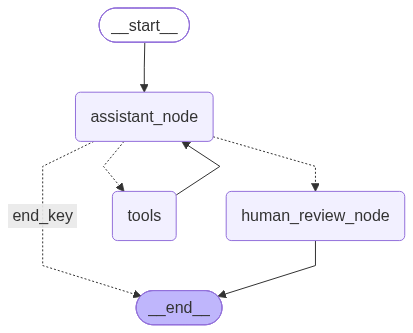

In [68]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

short_term_memory = MemorySaver()
graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)
graph_builder.add_node("human_review_node", human_review_node)
graph_builder.add_node("tools", ToolNode(ALL_TOOLS))

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_conditional_edges(
    "assistant_node",
    route_after_assistant_node,
    {
        "human_review_node": "human_review_node",
        "tools": "tools",
        "end_key": END
    }
)
graph_builder.add_edge("tools", "assistant_node")
graph = graph_builder.compile(checkpointer=short_term_memory)
graph

In [72]:
hitl_config = {"configurable": {"thread_id": "stock_session"}}
response = graph.invoke(
    {"messages": [{"role": "user", "content": "Please purchase Zensar stock with quantity 500"}]},
    hitl_config)

if "__interrupt__" in response:
    print("Graph execution paused for human review.")
    print(response["__interrupt__"])
else:
    print("Graph execution completed without human review.")
    print(response)




Graph execution paused for human review.
[Interrupt(value={'question': 'Shall I purachase this stock?', 'tool': 'purchase_stock', 'args': {'quantity': 500, 'stock': 'Zensar'}}, id='1cee0cb46ce17d1c4a050a1de4e03a2b')]


In [70]:
approve_command = Command(resume="approve")
approval_response = graph.invoke(approve_command, hitl_config)
print('Final answer')
print(approval_response)

Final answer
{'messages': [HumanMessage(content='Please purchase Zensar stock with quantity 500', additional_kwargs={}, response_metadata={}, id='275591d7-d719-4ca2-9a36-2ef837ee253b'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-26T05:48:11.514984506Z', 'done': True, 'done_reason': 'stop', 'total_duration': 1373442353, 'load_duration': None, 'prompt_eval_count': 275, 'prompt_eval_duration': None, 'eval_count': 75, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a176c0-7d04-7993-a52e-0783957a6ac3-0', tool_calls=[{'name': 'purchase_stock', 'args': {'quantity': 500, 'stock': 'Zensar'}, 'id': '36efdf55-9e48-42e8-b310-65902a0fa91f', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 275, 'output_tokens': 75, 'total_tokens': 350}), ToolMessage(content='Purchased 500 shares of Zensar', name='purchase_stock', id='456569e8-2351-40d7-a69

In [73]:
deny_command = Command(resume="deny")
deny_response = graph.invoke(deny_command, hitl_config)
print('Final answer')
print(deny_response)

Final answer
{'messages': [HumanMessage(content='Please purchase Zensar stock with quantity 500', additional_kwargs={}, response_metadata={}, id='275591d7-d719-4ca2-9a36-2ef837ee253b'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-26T05:48:11.514984506Z', 'done': True, 'done_reason': 'stop', 'total_duration': 1373442353, 'load_duration': None, 'prompt_eval_count': 275, 'prompt_eval_duration': None, 'eval_count': 75, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a176c0-7d04-7993-a52e-0783957a6ac3-0', tool_calls=[{'name': 'purchase_stock', 'args': {'quantity': 500, 'stock': 'Zensar'}, 'id': '36efdf55-9e48-42e8-b310-65902a0fa91f', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 275, 'output_tokens': 75, 'total_tokens': 350}), ToolMessage(content='Purchased 500 shares of Zensar', name='purchase_stock', id='456569e8-2351-40d7-a69